<a href="https://colab.research.google.com/github/keyvanmahmoudi/Machine_Learning_Course/blob/main/solutions/Session03_linear_regression_solutions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

# پاسخ تمرین‌های جلسهٔ ۳: رگرسیون خطی

این نوت‌بوک پاسخ پیشنهادی تمرین‌های انتهای [نوت‌بوک جلسه](../sessions/Session03_linear_regression.ipynb) است. قبل از دیدن پاسخ‌ها، خودتان تمرین‌ها را حل کنید؛ معمولاً بیش از یک راه‌حل درست وجود دارد.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### آماده‌سازی

</div>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
import seaborn as sns

sns.set_theme(style="whitegrid")

DATA_URL = "https://raw.githubusercontent.com/keyvanmahmoudi/Machine_Learning_Course/main/data/"
housing = pd.read_csv(DATA_URL + "housing.csv")
housing["rooms_per_household"] = housing["total_rooms"] / housing["households"]
housing["bedrooms_ratio"] = housing["total_bedrooms"] / housing["total_rooms"]
housing["people_per_household"] = housing["population"] / housing["households"]

def make_model():
    numeric = housing.drop(columns=["median_house_value", "ocean_proximity"]).columns.tolist()
    prep = ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), numeric),
        ("cat", OneHotEncoder(handle_unknown="ignore"), ["ocean_proximity"]),
    ])
    return Pipeline([("prep", prep), ("model", LinearRegression())])

def report(name, y_true, y_pred):
    return {"model": name, "MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": root_mean_squared_error(y_true, y_pred), "R2": r2_score(y_true, y_pred)}

X = housing.drop(columns="median_house_value")
y = housing["median_house_value"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۱

تابع `gradient_descent` را طوری تغییر کنید که **mini-batch** باشد: در هر قدم فقط ۱۶ نمونهٔ تصادفی استفاده شود. نمودار خطا را با نسخهٔ دسته‌ای مقایسه کنید.

</div>

Batch GD:      b = 3.946, w = 3.040
Mini-batch GD: b = 3.808, w = 3.157


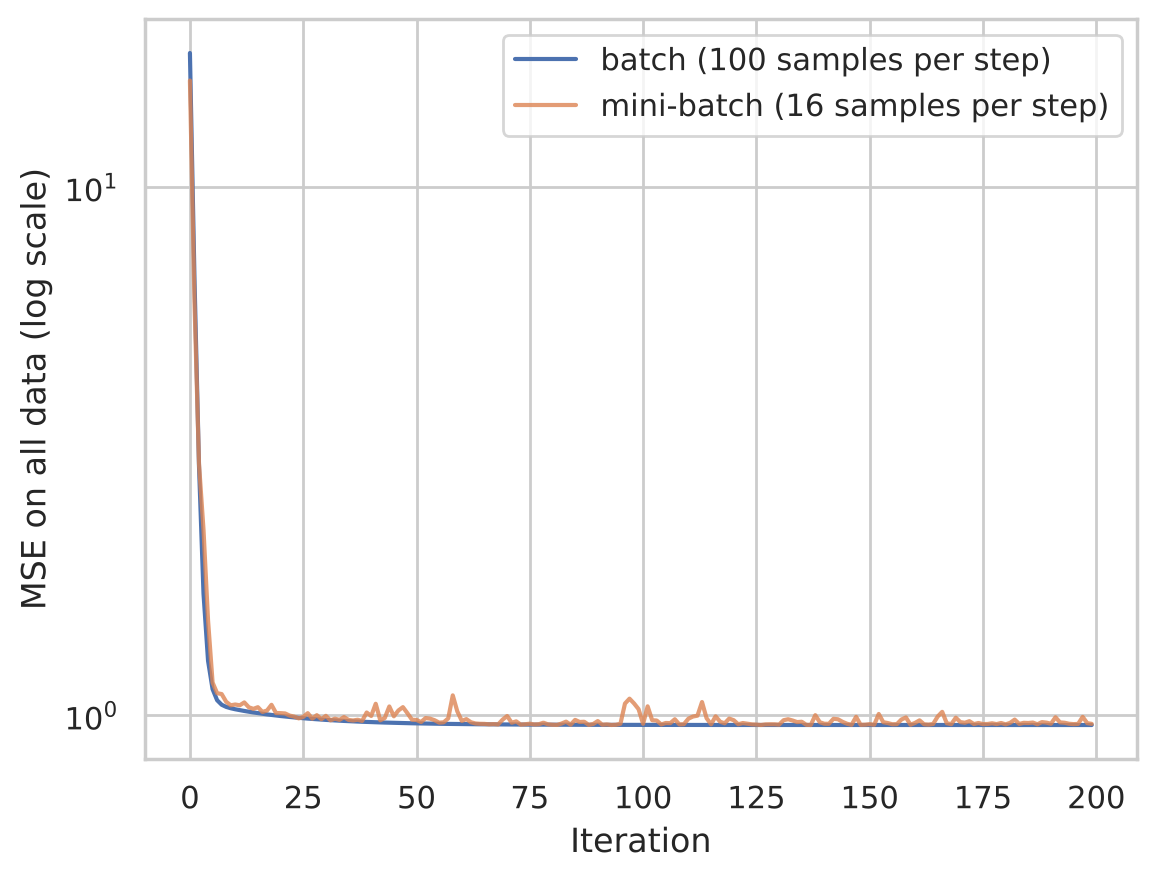

In [2]:
rng = np.random.default_rng(42)
x = 2 * rng.random(100)
y_toy = 4 + 3 * x + rng.normal(0, 1, 100)

def gradient_descent(x, y, learning_rate=0.1, n_iterations=200, batch_size=None, seed=0):
    rng = np.random.default_rng(seed)
    w, b, history = 0.0, 0.0, []
    for _ in range(n_iterations):
        idx = rng.choice(len(x), batch_size, replace=False) if batch_size else np.arange(len(x))
        xb, yb = x[idx], y[idx]
        error = w * xb + b - yb
        w -= learning_rate * 2 * np.mean(error * xb)
        b -= learning_rate * 2 * np.mean(error)
        history.append(np.mean((w * x + b - y) ** 2))      # loss on the full data, for comparison
    return w, b, history

w_full, b_full, hist_full = gradient_descent(x, y_toy)
w_mini, b_mini, hist_mini = gradient_descent(x, y_toy, batch_size=16)
print(f"Batch GD:      b = {b_full:.3f}, w = {w_full:.3f}")
print(f"Mini-batch GD: b = {b_mini:.3f}, w = {w_mini:.3f}")

plt.plot(hist_full, label="batch (100 samples per step)")
plt.plot(hist_mini, label="mini-batch (16 samples per step)", alpha=0.8)
plt.yscale("log")
plt.xlabel("Iteration")
plt.ylabel("MSE on all data (log scale)")
plt.legend()
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

هر دو روش به جواب نزدیک به $b = 4$ و $w = 3$ می‌رسند. منحنی mini-batch **پرنوسان‌تر** است، چون هر قدم فقط ۱۶ نمونه را می‌بیند و گرادیانش تخمینی نویزدار از گرادیان واقعی است. در عوض هر قدم آن حدود شش برابر ارزان‌تر است. برای داده‌های بسیار بزرگ (میلیون‌ها نمونه)، این صرفه‌جویی تعیین‌کننده است.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۲

رگرسیون خطی را فقط با ویژگی `median_income` آموزش دهید. $R^2$ چقدر است؟ ویژگی‌های دیگر چقدر کمک کرده‌اند؟

</div>

In [3]:
single = LinearRegression().fit(X_train[["median_income"]], y_train)
full = make_model().fit(X_train, y_train)
pd.DataFrame([
    report("median_income only", y_test, single.predict(X_test[["median_income"]])),
    report("all features", y_test, full.predict(X_test)),
]).round(3)

,model,MAE,RMSE,R2
0,median_income only,62990.865,84209.012,0.459
1,all features,49645.492,69127.038,0.635


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

`median_income` به‌تنهایی حدود نیمی از واریانس قیمت‌ها را توضیح می‌دهد. بقیهٔ ویژگی‌ها، به‌خصوص موقعیت جغرافیایی و نزدیکی به اقیانوس، $R^2$ را به حدود ۰٫۶۴ می‌رسانند و خطای متوسط را حدود ۱۰ هزار دلار کم می‌کنند.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۳

محله‌هایی را که قیمتشان دقیقاً ۵۰۰٬۰۰۱ است از دادهٔ آموزش و آزمون حذف کنید و مدل را دوباره آموزش دهید. معیارها چطور تغییر می‌کنند؟

</div>

In [4]:
capped_train = y_train >= 500_000
capped_test = y_test >= 500_000
print(f"Capped districts: {capped_train.sum()} in train, {capped_test.sum()} in test")

model_all = make_model().fit(X_train, y_train)
model_uncapped = make_model().fit(X_train[~capped_train], y_train[~capped_train])
pd.DataFrame([
    report("trained and tested on all data", y_test, model_all.predict(X_test)),
    report("capped districts removed", y_test[~capped_test], model_uncapped.predict(X_test[~capped_test])),
]).round(3)

Capped districts: 808 in train, 184 in test


,model,MAE,RMSE,R2
0,trained and tested on all data,49645.492,69127.038,0.635
1,capped districts removed,44252.450,60328.819,0.616


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

بعد از حذف محله‌های سقف‌خورده، MAE و RMSE کمتر می‌شوند ولی $R^2$ کمی پایین می‌آید (چون واریانس قیمت‌ها در دادهٔ باقی‌مانده کمتر است و مخرج $R^2$ کوچک‌تر شده)، چون بخش زیادی از بزرگ‌ترین خطاها مربوط به همین محله‌ها بود. ولی دقت کنید: این دو عدد **قابل مقایسهٔ مستقیم نیستند**، چون روی دو مجموعهٔ آزمون متفاوت حساب شده‌اند. حذف داده فقط وقتی درست است که در کاربرد واقعی هم چنین محله‌هایی نداشته باشیم؛ وگرنه مدل برای خانه‌های گران هیچ چیزی یاد نمی‌گیرد.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۴

به‌جای پیش‌بینی مستقیم قیمت، لگاریتم قیمت را پیش‌بینی کنید (`np.log`) و سپس با `np.exp` برگردانید. MAE بهتر می‌شود؟ (راهنمایی: `TransformedTargetRegressor`)

</div>

In [5]:
log_model = TransformedTargetRegressor(regressor=make_model(), func=np.log, inverse_func=np.exp)
log_model.fit(X_train, y_train)
pd.DataFrame([
    report("predict price", y_test, model_all.predict(X_test)),
    report("predict log(price)", y_test, log_model.predict(X_test)),
]).round(3)

,model,MAE,RMSE,R2
0,predict price,49645.492,69127.038,0.635
1,predict log(price),52059.892,90690.353,0.372


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

`TransformedTargetRegressor` هدف را قبل از آموزش با `np.log` تبدیل می‌کند و پیش‌بینی‌ها را با `np.exp` برمی‌گرداند، پس معیارها هنوز به دلار و قابل مقایسه‌اند.

نتیجه **بدتر** شد، به‌خصوص RMSE. دلیل: مدل خطی روی لگاریتم قیمت، برای چند محله پیش‌بینی بسیار بزرگی می‌دهد و `np.exp` این خطاها را **نمایی** بزرگ می‌کند؛ RMSE به این خطاهای بزرگ بسیار حساس است. علاوه بر این، مدل لگاریتمی خطای **نسبی** را کمینه می‌کند، نه خطای مطلق به دلار را.

درس مهم: تبدیل لگاریتمی هدف یک ترفند رایج است، ولی همیشه کمک نمی‌کند. هر تغییری را باید با معیار نهایی و روی دادهٔ اعتبارسنجی بسنجید، نه بر اساس انتظار.

</div>